# Repair calibration: first reviewer results
## What happened, what improved, and what remains unresolved

This notebook reports the **actual first repair-calibration run** on the deliberately weakened handcrafted XNOR circuit. GPT-6.2 Astra completed the adaptive protocol and submitted a valid edit. Qwen3.8-27B returned all proposed batches and a final edit before receiving any probe feedback; its session is incomplete and is **not scored as an adaptive result**.

These are calibration and development-validation observations, not main-study or held-out results. The fault was deliberately constructed, so the result is a controlled case study rather than evidence of general repair ability.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ROOT=Path.cwd().resolve()
if not (ROOT/'experiment.json').exists(): ROOT=ROOT.parent
if not (ROOT/'experiment.json').exists(): raise FileNotFoundError('Open from the project root or notebooks/.')
result=json.loads((ROOT/'results/repair_calibration_results.json').read_text())
astra,qwen=result['sessions']
probe_dir=ROOT/'responses/probes'/astra['session_id']
rounds=[json.loads((probe_dir/f'round-{i}.json').read_text()) for i in range(1,5)]
OUT=ROOT/'results'/'figures'; OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':300,'font.size':11,
                    'axes.spines.top':False,'axes.spines.right':False,
                    'axes.titleweight':'bold','figure.facecolor':'white'})
def save_figure(fig,name):
    fig.savefig(OUT/f'{name}.png',bbox_inches='tight',facecolor='white')
    fig.savefig(OUT/f'{name}.svg',bbox_inches='tight',facecolor='white')
print('Split:',result['data_split'],'— main study:',result['is_main_study'])
print('Loaded',len(rounds),'actual Astra probe rounds; no final evaluation data was loaded.')

Split: validation — main study: False
Loaded 4 actual Astra probe rounds; no final evaluation data was loaded.


## 1. Session outcomes

Both reviewers received the same starting weights, the intended XNOR task, and instructions for four rounds of eight adaptive probes. Their conversations were separate.

Astra returned one batch at a time and received the model's logits before choosing the next batch. Qwen's first reply included four batches and a final proposal at once; **zero probe rounds were delivered to it**. Qwen also reported more completion tokens than the requested output cap. Its original response is preserved, but it is excluded from the adaptive comparison.

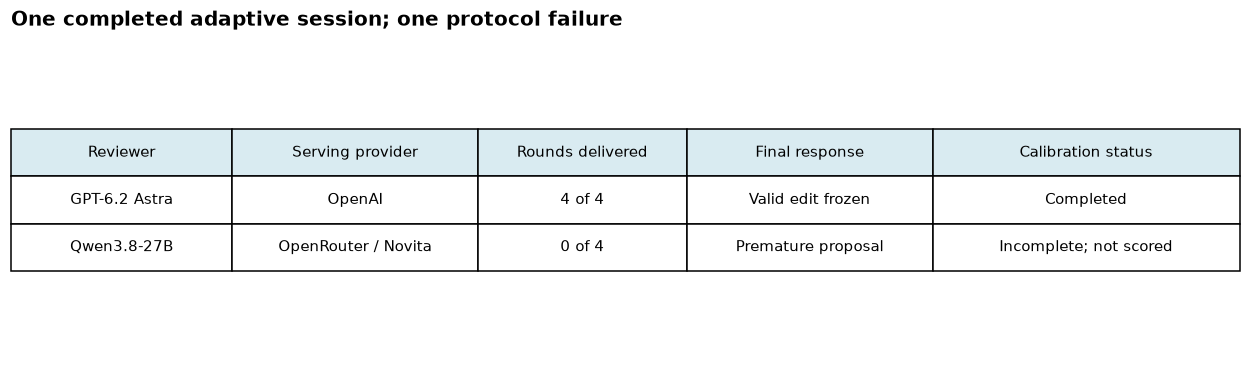

In [2]:
fig,ax=plt.subplots(figsize=(11.5,3.5)); ax.axis('off')
rows=[['GPT-6.2 Astra','OpenAI','4 of 4','Valid edit frozen','Completed'],
      ['Qwen3.8-27B','OpenRouter / Novita','0 of 4','Premature proposal','Incomplete; not scored']]
table=ax.table(cellText=rows,colLabels=['Reviewer','Serving provider','Rounds delivered','Final response','Calibration status'],
               cellLoc='center',loc='center',colColours=['#d9ebf1']*5,colWidths=[.18,.20,.17,.20,.25])
table.auto_set_font_size(False); table.set_fontsize(10); table.scale(1,2.4)
ax.set_title('One completed adaptive session; one protocol failure',loc='left',pad=10)
fig.tight_layout(); save_figure(fig,'19_calibration_outcomes'); plt.show()

## 2. Astra's probe sequence

The plot shows the first two coordinates of all 32 **reviewer-chosen** inputs. The symbols identify the round; the colors show whether the original model's prediction agreed with the known XNOR target for that exact query. These examples were selected by the reviewer and are not a random sample, so their error rate is not model accuracy.

Q++ means x₀ > 0 and x₁ > 0. The other coordinates can vary but are not visible in this two-dimensional projection. The four sets of logits were returned before Astra submitted its final edit.

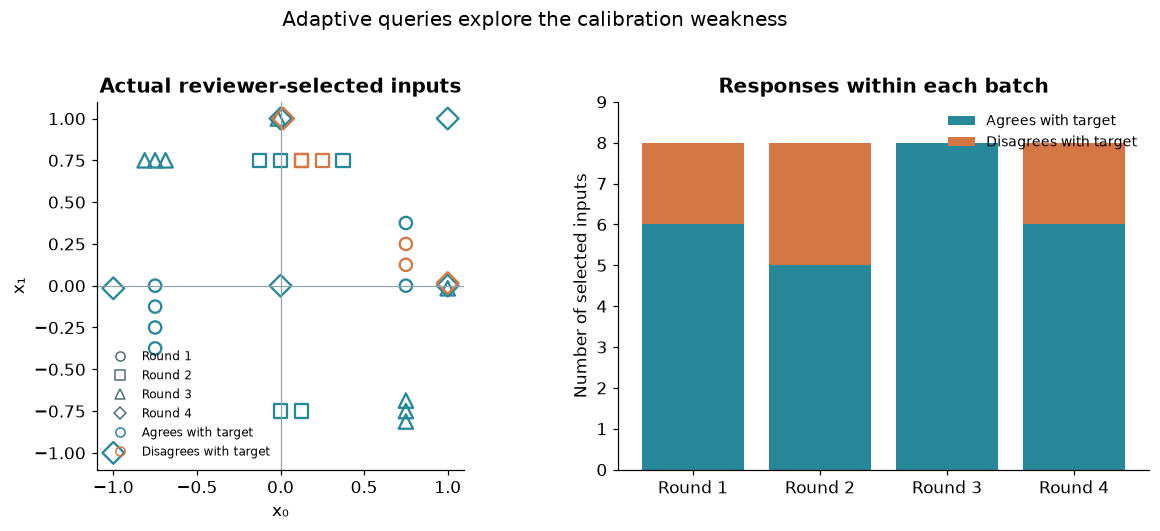

Reviewer-selected inputs by round (agreeing / total): [(6, 8), (5, 8), (8, 8), (6, 8)]
Selected-input counts are descriptive and are not an accuracy estimate.


In [3]:
fig,axes=plt.subplots(1,2,figsize=(11.5,4.7),gridspec_kw={'width_ratios':[1.2,1]})
markers=['o','s','^','D']; counts=[]
for i,record in enumerate(rounds):
    x=np.asarray(record['inputs']); logits=np.asarray(record['logits'])
    truth=(x[:,0]*x[:,1]>0); correct=(logits>0)==truth
    counts.append((int(correct.sum()),len(x)))
    for mask,color in [(correct,'#27889a'),(~correct,'#d47743')]:
        axes[0].scatter(x[mask,0],x[mask,1],s=65+12*i,marker=markers[i],
                        facecolors='none',edgecolors=color,linewidths=1.5)
axes[0].axhline(0,color='#94a4aa',lw=.8); axes[0].axvline(0,color='#94a4aa',lw=.8)
axes[0].set(xlim=(-1.1,1.1),ylim=(-1.1,1.1),xlabel='x₀',ylabel='x₁',title='Actual reviewer-selected inputs')
axes[0].set_aspect('equal')
from matplotlib.lines import Line2D
legend=[Line2D([0],[0],marker=m,linestyle='',color='#526c78',markerfacecolor='none',label=f'Round {i+1}') for i,m in enumerate(markers)]
legend += [Line2D([0],[0],marker='o',linestyle='',color=c,markerfacecolor='none',label=lab) for c,lab in [('#27889a','Agrees with target'),('#d47743','Disagrees with target')]]
axes[0].legend(handles=legend,frameon=False,fontsize=8,loc='lower left')
indices=np.arange(4); correct=np.array([v[0] for v in counts]); total=np.array([v[1] for v in counts])
axes[1].bar(indices,correct,color='#27889a',label='Agrees with target')
axes[1].bar(indices,total-correct,bottom=correct,color='#d47743',label='Disagrees with target')
axes[1].set(xticks=indices,xticklabels=[f'Round {i}' for i in range(1,5)],ylim=(0,9),
            ylabel='Number of selected inputs',title='Responses within each batch')
axes[1].legend(frameon=False,fontsize=9,loc='upper right')
fig.suptitle('Adaptive queries explore the calibration weakness',y=1.02,fontsize=13)
fig.tight_layout(); save_figure(fig,'20_astra_calibration_probes'); plt.show()
print('Reviewer-selected inputs by round (agreeing / total):',counts)
print('Selected-input counts are descriptive and are not an accuracy estimate.')

## 3. The proposed edit and validation result

Astra proposed multiplying **`fc2.weight[0, 0]` by 2**. The constructed calibration fault had halved that same value, so this edit restores the known reference weight. The proposal was frozen before the validation comparison.

On 1,024 development-validation examples, the starting model achieved 91.50% accuracy and the edited model achieved 100%. In Q++, accuracy increased from 66.02% to 100%; the other quadrants were already correct on this validation sample. The change is **+8.50 percentage points**, not an 8.50% relative increase.

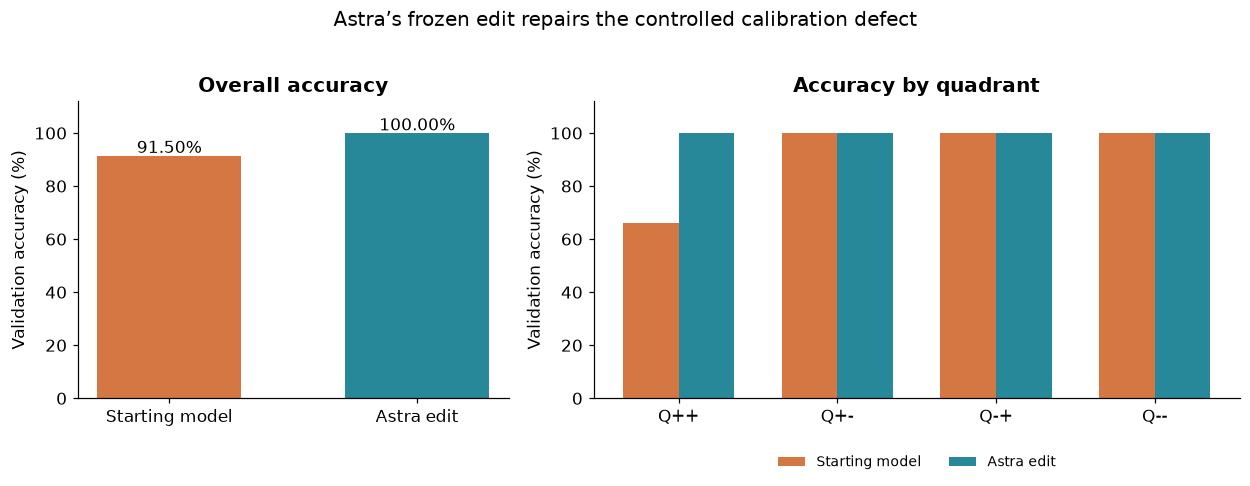

Edit: {'parameter': 'fc2.weight', 'index': [0, 0], 'scale': 2}
Validation accuracy change: +8.50 percentage points
Q++ validation examples: 256


In [4]:
qnames=['Q++','Q+-','Q-+','Q--']; before=astra['before']; after=astra['after']
fig,axes=plt.subplots(1,2,figsize=(11.5,4.4),gridspec_kw={'width_ratios':[1,1.5]})
bars=axes[0].bar(['Starting model','Astra edit'],[before['accuracy']*100,after['accuracy']*100],
                 color=['#d47743','#27889a'],width=.58)
for b in bars: axes[0].text(b.get_x()+b.get_width()/2,b.get_height()+1,f'{b.get_height():.2f}%',ha='center')
axes[0].set(ylim=(0,112),ylabel='Validation accuracy (%)',title='Overall accuracy')
pos=np.arange(4); width=.35
for offset,metrics,label,color in [(-width/2,before,'Starting model','#d47743'),(width/2,after,'Astra edit','#27889a')]:
    axes[1].bar(pos+offset,[metrics['quadrants'][q]['accuracy']*100 for q in qnames],width,label=label,color=color)
axes[1].set(xticks=pos,xticklabels=qnames,ylim=(0,112),ylabel='Validation accuracy (%)',title='Accuracy by quadrant')
axes[1].legend(frameon=False,fontsize=9,loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2)
fig.suptitle('Astra’s frozen edit repairs the controlled calibration defect',y=1.02,fontsize=13)
fig.tight_layout(); save_figure(fig,'21_astra_calibration_repair'); plt.show()
print('Edit:',astra['proposal'])
print('Validation accuracy change:',f"{astra['accuracy_change']*100:+.2f} percentage points")
print('Q++ validation examples:',before['quadrants']['Q++']['count'])

## 4. Token usage and spending

The figures below use the providers' returned usage metadata. OpenRouter reported its Qwen cost directly. OpenAI did not return a dollar amount, so its figure is an **estimate** calculated from returned token and cache counts and the standard rates documented on November 18, 2026: $8/million uncached input, $0.40/million cached input, $10/million 30-minute cache writes, and $40/million output. The final provider bill may differ. [OpenAI model pricing](https://developers.openai.com/api/docs/models/gpt-6.2-astra)

At the end of this initial run, the local ledger reserved more than the estimated spend because it uses conservative per-request estimates. Its $10 ceiling is **not a provider-side billing guarantee**. Qwen reported 7,628 completion tokens on a request with `max_tokens=4096`; the reason for the discrepancy is not established. The relay now stops before another call if a provider reports usage above that requested cap.

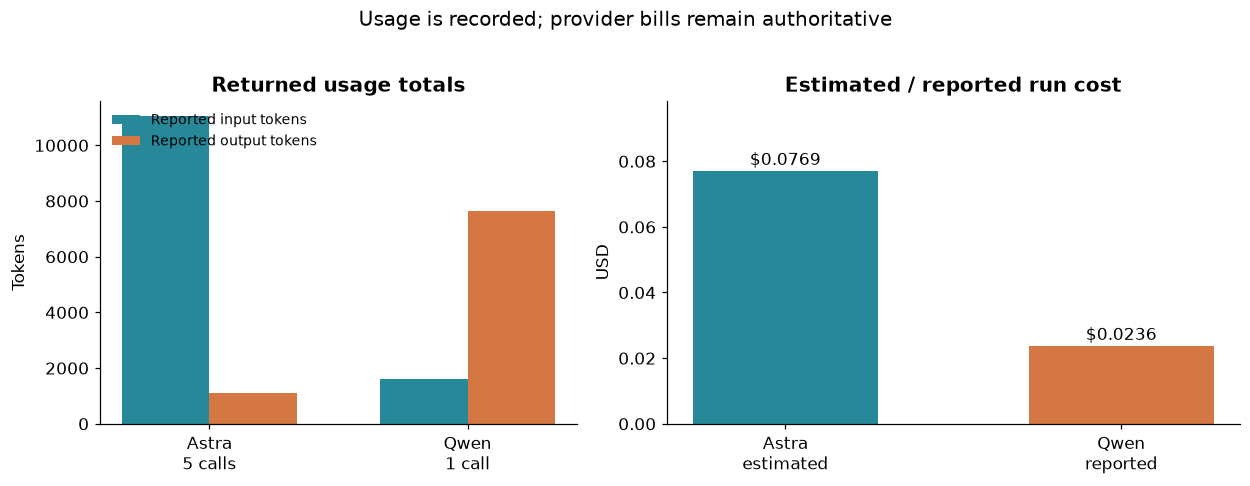

Reservation ledger after initial run: $8.2660 of $10.00
Reservation is not actual spending or a provider-side cap.
Qwen reported completion tokens: 7628 ; requested maximum: 4096


In [5]:
fig,axes=plt.subplots(1,2,figsize=(11.5,4.3),gridspec_kw={'width_ratios':[1,1.2]})
labels=['Astra\n5 calls','Qwen\n1 call']; inp=[astra['usage']['input_tokens'],qwen['usage']['input_tokens']]
out=[astra['usage']['output_tokens'],qwen['usage']['output_tokens']]
x=np.arange(2); width=.34
axes[0].bar(x-width/2,inp,width,label='Reported input tokens',color='#27889a')
axes[0].bar(x+width/2,out,width,label='Reported output tokens',color='#d47743')
axes[0].set(xticks=x,xticklabels=labels,ylabel='Tokens',title='Returned usage totals')
axes[0].legend(frameon=False,fontsize=9,loc='upper left')
vals=[astra['estimated_cost_usd'],qwen['reported_cost_usd']]
bars=axes[1].bar(['Astra\nestimated','Qwen\nreported'],vals,color=['#27889a','#d47743'],width=.55)
for b in bars: axes[1].text(b.get_x()+b.get_width()/2,b.get_height()+.002,f'${b.get_height():.4f}',ha='center')
axes[1].set(ylim=(0,max(vals)*1.28),ylabel='USD',title='Estimated / reported run cost')
fig.suptitle('Usage is recorded; provider bills remain authoritative',y=1.02,fontsize=13)
fig.tight_layout(); save_figure(fig,'22_calibration_usage'); plt.show()
print(f"Reservation ledger after initial run: ${result['initial_run_reserved_usd']:.4f} of ${result['local_reservation_limit_usd']:.2f}")
print('Reservation is not actual spending or a provider-side cap.')
print('Qwen reported completion tokens:',qwen['usage']['output_tokens'],'; requested maximum:',qwen['requested_max_output_tokens'])

## 5. Revised Qwen calibration

After the initial failure, a fresh Qwen session used a staged prompt that explicitly required one batch at a time. It completed all four probe rounds and submitted a valid edit. The edit restored the deliberately weakened calibration weight; validation accuracy rose from **91.50% to 100%**, including **66.02% to 100% in Q++**.

The first revised response reported 4,832 completion tokens against a requested maximum of 4,096. Its reported cost was within its reservation, and the already-returned response was explicitly accepted without retry. Astra and the revised Qwen session used different prompt versions, so these calibration observations are not a matched comparison.

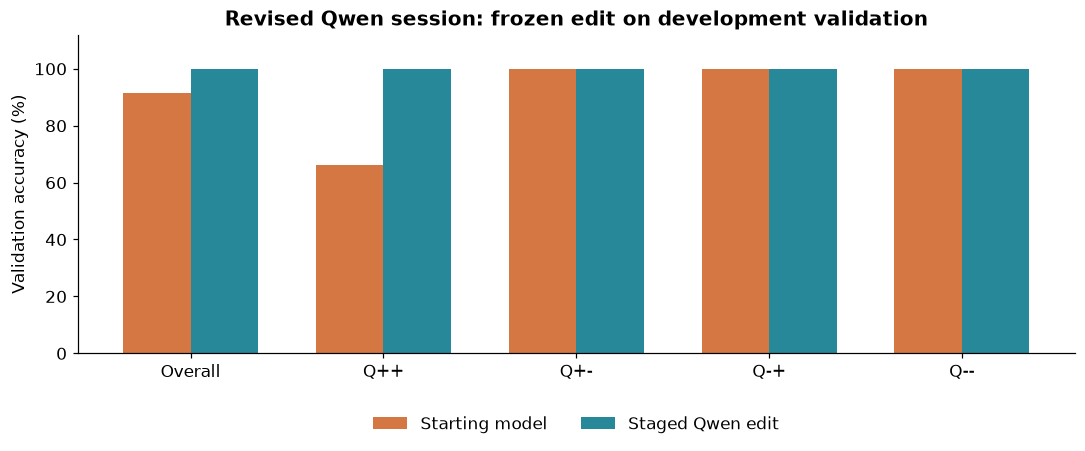

Probe rounds delivered: 4
Edit: {'parameter': 'fc2.weight', 'index': [0, 0], 'scale': 2.0}
Accuracy change: +8.50 percentage points
Revised Qwen reported cost: $0.04494


In [6]:
qwen_v2=result['revised_sessions'][0]
labels=['Overall','Q++','Q+-','Q-+','Q--']; before=qwen_v2['before']; after=qwen_v2['after']
left=[before['accuracy']]+[before['quadrants'][q]['accuracy'] for q in labels[1:]]
right=[after['accuracy']]+[after['quadrants'][q]['accuracy'] for q in labels[1:]]
fig,ax=plt.subplots(figsize=(10,4.3)); x=np.arange(len(labels)); width=.35
ax.bar(x-width/2,np.array(left)*100,width,label='Starting model',color='#d47743')
ax.bar(x+width/2,np.array(right)*100,width,label='Staged Qwen edit',color='#27889a')
ax.set(xticks=x,xticklabels=labels,ylim=(0,112),ylabel='Validation accuracy (%)',title='Revised Qwen session: frozen edit on development validation')
ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2)
fig.tight_layout(); save_figure(fig,'26_calibration_latest_qwen'); plt.show()
print('Probe rounds delivered:',qwen_v2['probe_rounds_delivered'])
print('Edit:',qwen_v2['proposal'])
print('Accuracy change:',f"{qwen_v2['accuracy_change']*100:+.2f} percentage points")
print('Revised Qwen reported cost:',f"${qwen_v2['reported_cost_usd']:.5f}")

The edit worked on the validation accuracy metric, but one part of Qwen's explanation was incorrect: for input `(0.5, 0, 0, 0)`, the logit changed from −1.25 to 0.0 even though the predicted class stayed 0. See [the staged Qwen notebook](07_qwen_staged_calibration.ipynb) for the detailed check. No held-out data was used.

## 6. Interpretation and next steps

- **Astra:** one completed calibration session produced an edit that reversed the deliberately introduced fault and improved development-validation accuracy. Its specific input choices and predictions are preserved in the session transcript. This does not show that probing caused the successful edit, or that the model would repair unseen defects.
- **Qwen:** the reply identified a possible edit but bypassed the staged interaction. It is preserved as an incomplete calibration, not scored as a completed adaptive run. A fresh staged-prompt session was completed later, as shown above.
- **Comparison:** the completed Astra and revised Qwen calibrations used different prompt versions, so they do not form a matched comparison. The main study still needs the finalized protocol, predeclared cohort, reviewer sessions, and a freeze before held-out evaluation.
- **Scope:** neither this notebook nor these results evaluate the separate ablation-prediction task. The final evaluation set remains untouched.